# Species Count — `fixed_batches_20`

Counts the number of species folders in each batch inside `fixed_batches_20`,
and reports the grand total across all 20 batches.

In [1]:
from pathlib import Path
import pandas as pd

base_dir = Path("../fixed_batches_20")

rows = []
for batch_dir in sorted(base_dir.iterdir()):
    if not batch_dir.is_dir() or not batch_dir.name.startswith("batch_"):
        continue
    species = [d for d in batch_dir.iterdir() if d.is_dir()]
    rows.append({"Batch": batch_dir.name, "Species Count": len(species)})

df = pd.DataFrame(rows)

totals_row = pd.DataFrame([{"Batch": "TOTAL", "Species Count": df["Species Count"].sum()}])
df_display = pd.concat([df, totals_row], ignore_index=True)

df_display

,Batch,Species Count
0,batch_01,373
1,batch_02,373
2,batch_03,373
3,batch_04,373
4,batch_05,373
5,batch_06,373
6,batch_07,373
7,batch_08,373
8,batch_09,373
9,batch_10,373


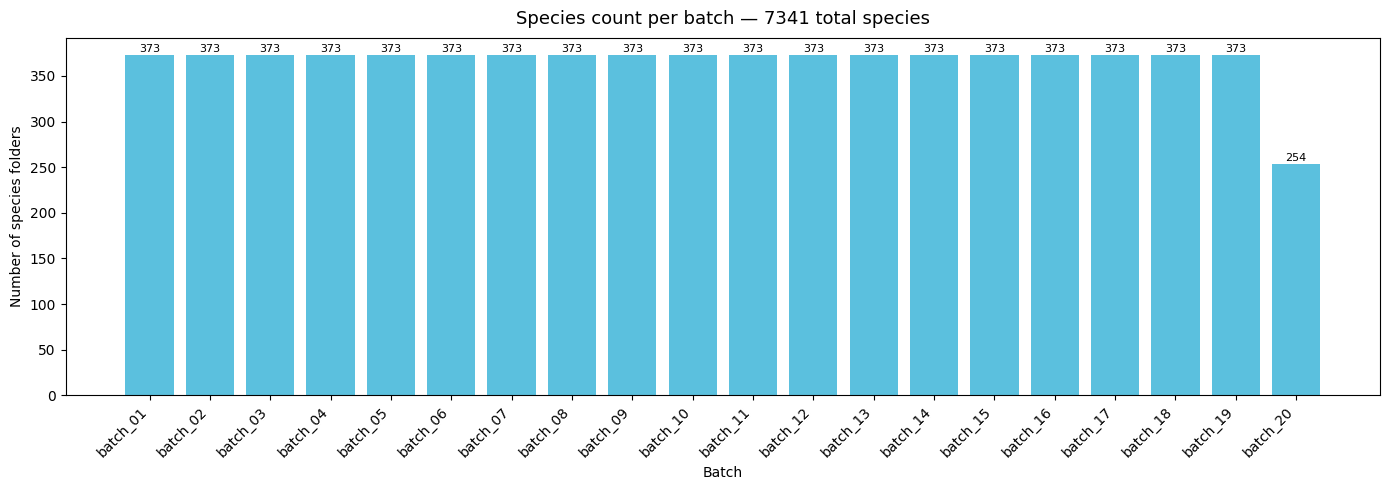

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(df["Batch"], df["Species Count"], color="#5bc0de")
ax.set_title(f"Species count per batch — {df['Species Count'].sum()} total species", fontsize=13, pad=10)
ax.set_xlabel("Batch")
ax.set_ylabel("Number of species folders")
ax.set_xticks(range(len(df)))
ax.set_xticklabels(df["Batch"], rotation=45, ha="right")
for i, row in df.iterrows():
    ax.text(i, row["Species Count"] + 3, str(row["Species Count"]), ha="center", fontsize=8)
plt.tight_layout()
plt.show()

In [3]:

# Check for duplicate species folder names across batches
from collections import Counter

all_species = []
for batch_dir in sorted(base_dir.iterdir()):
    if not batch_dir.is_dir() or not batch_dir.name.startswith("batch_"):
        continue
    for species_dir in batch_dir.iterdir():
        if species_dir.is_dir():
            all_species.append((species_dir.name, batch_dir.name))

name_counts = Counter(name for name, _ in all_species)
duplicates = {name: count for name, count in name_counts.items() if count > 1}

if duplicates:
    dup_records = [(name, batch) for name, batch in all_species if name in duplicates]
    df_dup = pd.DataFrame(dup_records, columns=["Species", "Batch"]).sort_values("Species")
    print(f"Found {len(duplicates)} species appearing in more than one batch:\n")
    print(df_dup.to_string(index=False))
else:
    print(f"No duplicates found. All {len(all_species)} species folders are unique.")


Found 3 species appearing in more than one batch:

             Species    Batch
         with_errors batch_10
         with_errors batch_19
         with_errors batch_18
         with_errors batch_17
         with_errors batch_16
         with_errors batch_15
         with_errors batch_14
         with_errors batch_13
         with_errors batch_12
         with_errors batch_11
         with_errors batch_09
         with_errors batch_08
         with_errors batch_07
         with_errors batch_06
         with_errors batch_20
         with_errors batch_04
         with_errors batch_05
         with_errors batch_01
         with_errors batch_02
         with_errors batch_03
      without_errors batch_13
      without_errors batch_14
      without_errors batch_03
      without_errors batch_15
      without_errors batch_06
      without_errors batch_17
      without_errors batch_02
      without_errors batch_18
      without_errors batch_19
      without_errors batch_20
      without_error

In [4]:
import shutil

EXCLUDE = {"with_errors", "without_errors", "without_reprod_annot"}

src_dir  = Path("../fixed_batches_20")
dest_dir = Path("../fixed_batches_20_clean")

if dest_dir.exists():
    print(f"{dest_dir} already exists — delete it first to re-run.")
else:
    dest_dir.mkdir()
    copied_batches = 0
    copied_species = 0
    skipped = 0

    for batch_dir in sorted(src_dir.iterdir()):
        if not batch_dir.is_dir() or not batch_dir.name.startswith("batch_"):
            continue
        dest_batch = dest_dir / batch_dir.name
        dest_batch.mkdir()
        copied_batches += 1

        for item in batch_dir.iterdir():
            if item.is_dir() and item.name in EXCLUDE:
                skipped += 1
                continue
            if item.is_dir():
                shutil.copytree(item, dest_batch / item.name)
                copied_species += 1
            else:
                shutil.copy2(item, dest_batch / item.name)

    print(f"Done.")
    print(f"  Batches copied : {copied_batches}")
    print(f"  Species copied : {copied_species}")
    print(f"  Folders skipped: {skipped}  {EXCLUDE}")


Done.
  Batches copied : 20
  Species copied : 7281
  Folders skipped: 60  {'with_errors', 'without_reprod_annot', 'without_errors'}


In [5]:
from pathlib import Path
import pandas as pd

base_dir = Path("../fixed_batches_20_clean")

rows = []
for batch_dir in sorted(base_dir.iterdir()):
    if not batch_dir.is_dir() or not batch_dir.name.startswith("batch_"):
        continue
    species = [d for d in batch_dir.iterdir() if d.is_dir()]
    rows.append({"Batch": batch_dir.name, "Species Count": len(species)})

df = pd.DataFrame(rows)

totals_row = pd.DataFrame([{"Batch": "TOTAL", "Species Count": df["Species Count"].sum()}])
df_display = pd.concat([df, totals_row], ignore_index=True)

df_display

,Batch,Species Count
0,batch_01,370
1,batch_02,370
2,batch_03,370
3,batch_04,370
4,batch_05,370
5,batch_06,370
6,batch_07,370
7,batch_08,370
8,batch_09,370
9,batch_10,370
